In [ ]:
#Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from IPython.display import display

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
#Load the dataset

df = pd.read_csv(
    '../data/interim/logistics_analytical_dataset.csv'
)

print("Dataset loaded successfully!")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (99441, 39)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,has_invalid_timestamps,is_delivered,...,total_weight_g,review_score,min_review_score,review_count,has_review_comment,is_interstate,purchase_year,purchase_year_month,purchase_weekday,purchase_hour
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,True,...,500.0,4.0,4.0,1.0,1.0,False,2017,2017-10,Monday,10
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,True,...,400.0,4.0,4.0,1.0,1.0,True,2018,2018-07,Tuesday,20
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,True,...,420.0,5.0,5.0,1.0,0.0,True,2018,2018-08,Wednesday,8
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,True,...,450.0,5.0,5.0,1.0,1.0,True,2017,2017-11,Saturday,19
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,True,...,250.0,5.0,5.0,1.0,0.0,False,2018,2018-02,Tuesday,21


In [ ]:
#Inspect the geographical columns

print("Column Names:")
print(df.columns.tolist())

print("\nCustomer State:")
print(df['customer_state'].value_counts().head())

print("\nSeller State:")
print(df['seller_state'].value_counts().head())

print("\nInterstate Information:")
print(df['is_interstate'].value_counts(dropna=False))

In [ ]:
#Filter eligible orders

valid = df[df['is_eligible_otd'] == 1].copy()

print("Total orders:", len(df))
print("Eligible orders:", len(valid))
print("Excluded orders:", len(df) - len(valid))

In [ ]:
#Task 1 – Intrastate vs Interstate comparison

intra_vs_inter = valid.groupby('is_interstate').agg(
    order_count=('order_id', 'count'),

    median_duration=(
        'total_delivery_duration_days',
        'median'
    ),

    delay_rate=(
        'delivery_outcome',
        lambda x: (x == 'delayed').mean() * 100
    ),

    avg_freight=('total_freight_value', 'mean')
)

print("Intrastate (False) vs Interstate (True):")

display(intra_vs_inter.round(2))

In [ ]:
#Perform the comparison

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

labels = ['Intrastate', 'Interstate']

# Delivery duration
axes[0].bar(
    labels,
    intra_vs_inter['median_duration']
)
axes[0].set_title('Median Delivery Duration')
axes[0].set_ylabel('Days')

# Delay rate
axes[1].bar(
    labels,
    intra_vs_inter['delay_rate']
)
axes[1].set_title('Delivery Delay Rate')
axes[1].set_ylabel('Delay Rate (%)')

# Freight cost
axes[2].bar(
    labels,
    intra_vs_inter['avg_freight']
)
axes[2].set_title('Average Freight Cost')
axes[2].set_ylabel('Freight Value')

plt.tight_layout()
plt.show()

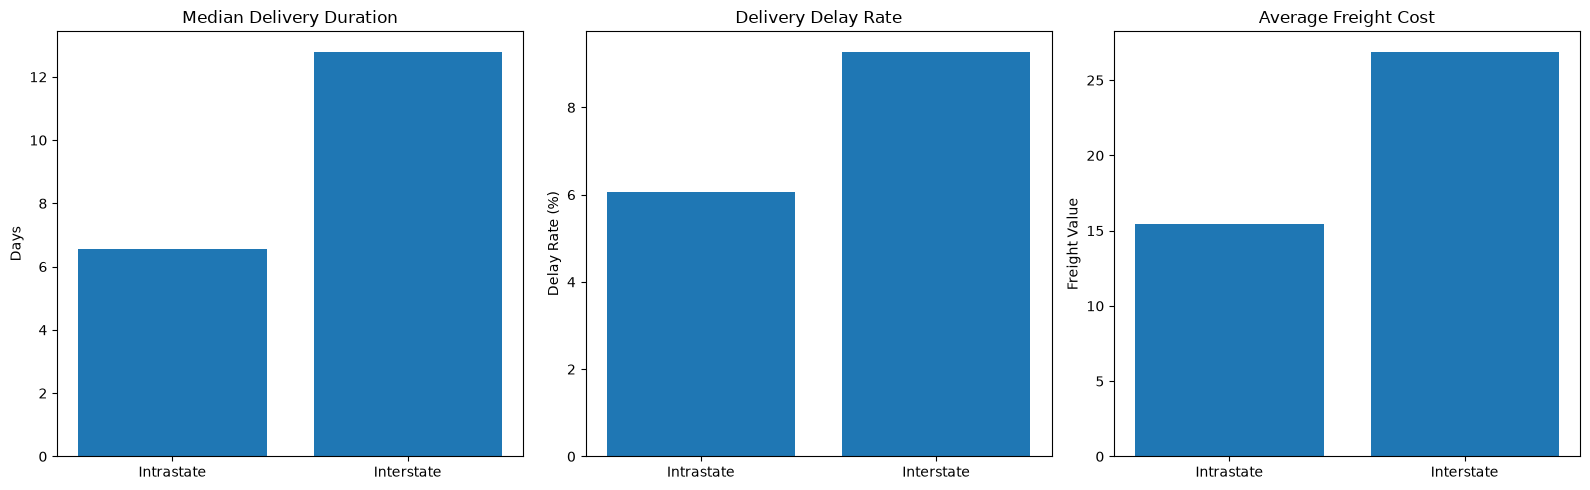

In [7]:
#Visualize the comparison

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

labels = ['Intrastate', 'Interstate']

# Delivery duration
axes[0].bar(
    labels,
    intra_vs_inter['median_duration']
)
axes[0].set_title('Median Delivery Duration')
axes[0].set_ylabel('Days')

# Delay rate
axes[1].bar(
    labels,
    intra_vs_inter['delay_rate']
)
axes[1].set_title('Delivery Delay Rate')
axes[1].set_ylabel('Delay Rate (%)')

# Freight cost
axes[2].bar(
    labels,
    intra_vs_inter['avg_freight']
)
axes[2].set_title('Average Freight Cost')
axes[2].set_ylabel('Freight Value')

plt.tight_layout()
plt.show()

In [8]:
#Task 2 – Destination State Analysis
#Calculate state-wise performance

state_perf = valid.groupby('customer_state').agg(
    orders=('order_id', 'count'),

    median_days=(
        'total_delivery_duration_days',
        'median'
    ),

    delay_pct=(
        'delivery_outcome',
        lambda x: (x == 'delayed').mean() * 100
    )
)

# Remove states with fewer than 20 orders
state_perf = state_perf[
    state_perf['orders'] >= 20
]

state_perf = state_perf.sort_values(
    'delay_pct',
    ascending=False
)

display(state_perf.round(2))


,orders,median_days,delay_pct
customer_state,,,
AL,397,22.33,23.93
MA,714,19.21,19.75
PI,473,16.33,16.07
CE,1278,18.21,15.34
SE,334,18.03,15.27
BA,3252,16.91,14.02
RJ,12330,12.05,13.50
TO,273,15.88,12.82
PA,945,21.08,12.38


In [9]:
#Identify the top 10 problematic states

top_states = state_perf.head(10)

print("Top 10 States with Highest Delay Rates:")

display(top_states.round(2))

Top 10 States with Highest Delay Rates:


,orders,median_days,delay_pct
customer_state,,,
AL,397,22.33,23.93
MA,714,19.21,19.75
PI,473,16.33,16.07
CE,1278,18.21,15.34
SE,334,18.03,15.27
BA,3252,16.91,14.02
RJ,12330,12.05,13.50
TO,273,15.88,12.82
PA,945,21.08,12.38


In [12]:
#Task 3 – Identify the five most problematic shipping corridors
#Group orders by shipping corridor

corridor_perf = valid.groupby(
    ['seller_state', 'customer_state']
).agg(

    order_count=('order_id', 'count'),

    median_days=(
        'total_delivery_duration_days',
        'median'
    ),

    delay_rate=(
        'delivery_outcome',
        lambda x: (x == 'delayed').mean() * 100
    ),

    avg_freight=('total_freight_value', 'mean')

).reset_index()

In [14]:
#Filter and identify the top five corridors

# Keep corridors with at least 20 orders

corridor_perf = corridor_perf[
    corridor_perf['order_count'] >= 20
].copy()

# Create corridor name

corridor_perf['corridor'] = (
    corridor_perf['seller_state']
    + ' → '
    + corridor_perf['customer_state']
)

# Sort by highest delay rate

top_5_corridors = corridor_perf.sort_values(
    by='delay_rate',
    ascending=False
).head(5)

print("Top 5 Most Problematic Shipping Corridors:")

display(
    top_5_corridors[
        [
            'corridor',
            'order_count',
            'median_days',
            'delay_rate',
            'avg_freight'
        ]
    ].round(2)
)

Top 5 Most Problematic Shipping Corridors:


,corridor,order_count,median_days,delay_rate,avg_freight
252,PR → AL,36,26.46,38.89,48.99
355,SC → CE,22,20.51,27.27,68.48
383,SP → AL,255,22.97,26.27,36.63
141,MA → SP,123,13.47,25.20,33.87
283,RJ → CE,54,20.33,22.22,35.60


In [15]:
#Task 4 – Create the Regional Delay Matrix
#Prepare the matrix

# Select the 10 states with the highest order volume

top_10_states = (
    valid['customer_state']
    .value_counts()
    .head(10)
    .index
)

# Filter corridors for these states

matrix_data = corridor_perf[
    corridor_perf['seller_state'].isin(top_10_states)
    &
    corridor_perf['customer_state'].isin(top_10_states)
].copy()

# Create origin-destination matrix

regional_matrix = matrix_data.pivot(
    index='seller_state',
    columns='customer_state',
    values='delay_rate'
)

display(regional_matrix.round(2))

customer_state,BA,DF,ES,GO,MG,PR,RJ,RS,SC,SP
seller_state,,,,,,,,,,
BA,9.09,NaN,NaN,NaN,0.00,NaN,6.02,4.55,NaN,5.11
DF,5.71,6.12,NaN,3.33,0.98,0.00,7.37,13.64,19.05,2.92
ES,4.35,NaN,NaN,NaN,0.00,NaN,8.47,NaN,NaN,10.00
GO,NaN,7.14,NaN,3.33,1.20,NaN,5.36,NaN,NaN,3.97
MG,10.41,3.24,4.68,2.67,3.17,1.94,9.36,5.04,8.80,4.33
PR,16.78,4.05,9.09,4.60,5.26,4.35,14.03,5.23,6.68,3.53
RJ,11.11,8.33,2.02,7.34,7.27,8.91,6.50,9.64,10.62,9.10
RS,16.67,2.13,4.17,0.00,2.69,5.07,8.54,5.21,0.00,2.26
SC,13.16,1.45,4.00,9.26,5.15,3.16,10.21,6.19,6.30,4.38


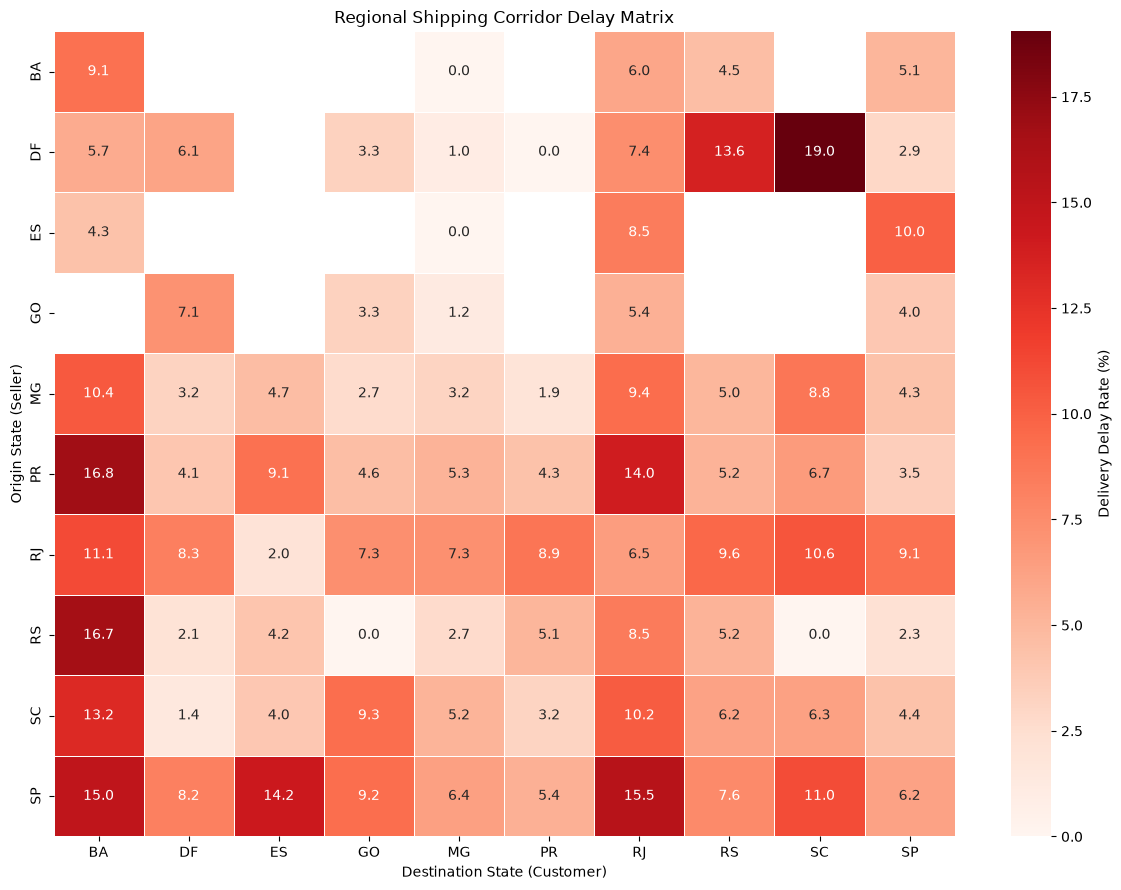

Chart saved successfully!
File location: c:\Users\sugit\ecommerce-delivery-logistics-analysis\reports\figures\regional_delay_matrix.png
File exists: True


In [23]:
#Plot the heatmap
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# Identify project root automatically
current_path = Path.cwd()

if (current_path / 'data').exists():
    project_root = current_path
else:
    project_root = current_path.parent

# Create figures directory
figures_dir = project_root / 'reports' / 'figures'
figures_dir.mkdir(parents=True, exist_ok=True)

# Create heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    regional_matrix,
    annot=True,
    fmt='.1f',
    cmap='Reds',
    linewidths=0.5,
    cbar_kws={'label': 'Delivery Delay Rate (%)'}
)

plt.title('Regional Shipping Corridor Delay Matrix')
plt.xlabel('Destination State (Customer)')
plt.ylabel('Origin State (Seller)')

plt.tight_layout()

# Save image
output_file = figures_dir / 'regional_delay_matrix.png'

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Chart saved successfully!")
print("File location:", output_file)
print("File exists:", output_file.exists())

In [19]:
#Task 5 – Distance Bands (additional analysis)
#Inspect geographical information

geo_columns = [
    col for col in df.columns
    if any(word in col.lower() for word in [
        'lat', 'lon', 'long', 'distance', 'geo'
    ])
]

print("Available geographical columns:")
print(geo_columns)

Available geographical columns:
[]


In [22]:
import os

print(os.getcwd())

c:\Users\sugit\ecommerce-delivery-logistics-analysis\notebooks
